In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import sklearn.metrics
from sklearn.linear_model import Lasso

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
# Чтение данных из файла CSV
data = pd.read_csv(r'/content/drive/MyDrive/Video_Games.csv')

In [20]:
data1 = data.copy()

In [21]:
data1.drop(['Name', 'JP_Sales'], axis = 1, inplace = True)

In [22]:
data

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Rapala Trophies,PSP,2006.0,Sports,Activision,0.04,0.00,0.00,0.00,NaN,NaN,NaN,NaN,Sand Grain Studios,E
1,New Super Mario Bros. U,WiiU,2012.0,Platform,Nintendo,2.30,1.34,1.27,0.32,84.0,70.0,8.1,733.0,Nintendo,E
2,Robots,PS2,2005.0,Action,Vivendi Games,0.18,0.14,0.00,0.05,53.0,6.0,6.0,8.0,Eurocom Entertainment Software,E
3,Hamster Club 3,GBA,2002.0,Simulation,Jorudan,0.00,0.00,0.35,0.01,NaN,NaN,NaN,NaN,NaN,NaN
4,Formula 1 06,PS2,2006.0,Racing,Sony Computer Entertainment,0.00,0.00,0.04,0.00,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11698,Call of Duty: Black Ops,X360,2010.0,Shooter,Activision,9.70,3.68,0.11,1.13,87.0,89.0,6.3,1454.0,Treyarch,M
11699,Resistance 3,PS3,2011.0,Shooter,Sony Computer Entertainment,0.64,0.57,0.05,0.22,83.0,91.0,7.8,543.0,Insomniac Games,M
11700,Ready 2 Rumble Revolution,Wii,2009.0,Sports,Atari,0.15,0.00,0.00,0.01,37.0,31.0,NaN,NaN,10tacle Studios,T
11701,Monster Hunter Frontier Online: Forward 2,X360,2011.0,Role-Playing,Capcom,0.00,0.00,0.03,0.00,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11703 entries, 0 to 11702
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             11702 non-null  object 
 1   Platform         11703 non-null  object 
 2   Year_of_Release  11508 non-null  float64
 3   Genre            11702 non-null  object 
 4   Publisher        11665 non-null  object 
 5   NA_Sales         11703 non-null  float64
 6   EU_Sales         11703 non-null  float64
 7   JP_Sales         11703 non-null  float64
 8   Other_Sales      11703 non-null  float64
 9   Critic_Score     5676 non-null   float64
 10  Critic_Count     5676 non-null   float64
 11  User_Score       5319 non-null   float64
 12  User_Count       5319 non-null   float64
 13  Developer        7064 non-null   object 
 14  Rating           6957 non-null   object 
dtypes: float64(9), object(6)
memory usage: 1.3+ MB


In [24]:
data.shape

(11703, 15)

In [25]:
data.describe()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count
count,11508.000000,11703.000000,11703.000000,11703.000000,11703.000000,5676.000000,5676.000000,5319.000000,5319.000000
mean,2006.519465,0.269527,0.147226,0.079129,0.047640,69.057787,26.496124,7.132995,158.593345
std,5.922082,0.887505,0.527578,0.319529,0.189604,13.959621,18.998469,1.492816,515.113357
min,1980.000000,0.000000,0.000000,0.000000,0.000000,17.000000,4.000000,0.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000,12.000000,6.400000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000,22.000000,7.500000,25.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,80.000000,37.000000,8.200000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,98.000000,107.000000,9.600000,9629.000000


In [26]:
y = data.JP_Sales
# удаляем два столбца из датафрейма
data.drop(['Name', 'JP_Sales'], axis = 1, inplace = True)

In [27]:
# разделяем столбцы DataFrame на категориальные и числовые признаки
categorical_features = []
categorical_features_nos = []
numeric_features = []
i = 0
for col in data.columns:
  if data[col].dtype == object:
    categorical_features.append(col)
    categorical_features_nos.append(i)
  else:
    numeric_features.append(col)
  i += 1
categorical_features_nos

[0, 2, 3, 11, 12]

In [28]:
numeric_features

['Year_of_Release',
 'NA_Sales',
 'EU_Sales',
 'Other_Sales',
 'Critic_Score',
 'Critic_Count',
 'User_Score',
 'User_Count']

In [29]:
data.shape

(11703, 13)

In [30]:
data = data.fillna(-100)

In [31]:
data

,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,PSP,2006.0,Sports,Activision,0.04,0.00,0.00,-100.0,-100.0,-100.0,-100.0,Sand Grain Studios,E
1,WiiU,2012.0,Platform,Nintendo,2.30,1.34,0.32,84.0,70.0,8.1,733.0,Nintendo,E
2,PS2,2005.0,Action,Vivendi Games,0.18,0.14,0.05,53.0,6.0,6.0,8.0,Eurocom Entertainment Software,E
3,GBA,2002.0,Simulation,Jorudan,0.00,0.00,0.01,-100.0,-100.0,-100.0,-100.0,-100,-100
4,PS2,2006.0,Racing,Sony Computer Entertainment,0.00,0.00,0.00,-100.0,-100.0,-100.0,-100.0,-100,-100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11698,X360,2010.0,Shooter,Activision,9.70,3.68,1.13,87.0,89.0,6.3,1454.0,Treyarch,M
11699,PS3,2011.0,Shooter,Sony Computer Entertainment,0.64,0.57,0.22,83.0,91.0,7.8,543.0,Insomniac Games,M
11700,Wii,2009.0,Sports,Atari,0.15,0.00,0.01,37.0,31.0,-100.0,-100.0,10tacle Studios,T
11701,X360,2011.0,Role-Playing,Capcom,0.00,0.00,0.00,-100.0,-100.0,-100.0,-100.0,-100,-100


In [32]:
data[numeric_features].describe()

,Year_of_Release,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count
count,11703.000000,11703.000000,11703.000000,11703.000000,11703.000000,11703.000000,11703.000000,11703.000000
mean,1971.419807,0.269527,0.147226,0.047640,-18.006323,-38.648893,-51.308177,17.530377
std,269.716196,0.887505,0.527578,0.189604,85.051874,64.591816,53.356004,370.358961
min,-100.000000,0.000000,0.000000,0.000000,-100.000000,-100.000000,-100.000000,-100.000000
25%,2003.000000,0.000000,0.000000,0.000000,-100.000000,-100.000000,-100.000000,-100.000000
50%,2007.000000,0.080000,0.020000,0.010000,-100.000000,-100.000000,-100.000000,-100.000000
75%,2010.000000,0.240000,0.110000,0.030000,70.000000,21.000000,7.300000,20.000000
max,2020.000000,41.360000,28.960000,10.570000,98.000000,107.000000,9.600000,9629.000000


In [34]:
data[numeric_features] = (data[numeric_features] - data[numeric_features].mean()) / data[numeric_features].std()


In [35]:
data[numeric_features]

,Year_of_Release,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count
0,0.128210,-0.258621,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342
1,0.150455,2.287843,2.260848,1.436467,1.199342,1.682085,1.113430,1.931827
2,0.124502,-0.100875,-0.013697,0.012447,0.834859,0.691247,1.074072,-0.025733
3,0.113379,-0.303691,-0.279061,-0.198519,-0.964043,-0.949828,-0.912584,-0.317342
4,0.128210,-0.303691,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342
...,...,...,...,...,...,...,...,...
11698,0.143040,10.625822,6.696211,5.708528,1.234615,1.976239,1.079694,3.878587
11699,0.146748,0.417431,0.801348,0.909053,1.187585,2.007203,1.107807,1.418812
11700,0.139332,-0.134678,-0.279061,-0.198519,0.646739,1.078293,-0.912584,-0.317342
11701,0.146748,-0.303691,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342


In [37]:
pd.get_dummies(data[categorical_features]).astype(int)


,Platform_2600,Platform_3DO,Platform_3DS,Platform_DC,Platform_DS,Platform_GB,Platform_GBA,Platform_GC,Platform_GEN,Platform_GG,...,Developer_zSlide,Rating_-100,Rating_AO,Rating_E,Rating_E10+,Rating_EC,Rating_K-A,Rating_M,Rating_RP,Rating_T
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11698,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
11699,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
11700,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
11701,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [38]:
print(data.isna().sum())

Platform           0
Year_of_Release    0
Genre              0
Publisher          0
NA_Sales           0
EU_Sales           0
Other_Sales        0
Critic_Score       0
Critic_Count       0
User_Score         0
User_Count         0
Developer          0
Rating             0
dtype: int64


In [40]:
# В результате x будет новым DataFrame, содержащим все числовые столбцы и one-hot закодированные категориальные столбцы
x = pd.concat([data[numeric_features], pd.get_dummies(data[categorical_features]).astype(int)], axis=1)
x

,Year_of_Release,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Platform_2600,Platform_3DO,...,Developer_zSlide,Rating_-100,Rating_AO,Rating_E,Rating_E10+,Rating_EC,Rating_K-A,Rating_M,Rating_RP,Rating_T
0,0.128210,-0.258621,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0.150455,2.287843,2.260848,1.436467,1.199342,1.682085,1.113430,1.931827,0,0,...,0,0,0,1,0,0,0,0,0,0
2,0.124502,-0.100875,-0.013697,0.012447,0.834859,0.691247,1.074072,-0.025733,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0.113379,-0.303691,-0.279061,-0.198519,-0.964043,-0.949828,-0.912584,-0.317342,0,0,...,0,1,0,0,0,0,0,0,0,0
4,0.128210,-0.303691,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11698,0.143040,10.625822,6.696211,5.708528,1.234615,1.976239,1.079694,3.878587,0,0,...,0,0,0,0,0,0,0,1,0,0
11699,0.146748,0.417431,0.801348,0.909053,1.187585,2.007203,1.107807,1.418812,0,0,...,0,0,0,0,0,0,0,1,0,0
11700,0.139332,-0.134678,-0.279061,-0.198519,0.646739,1.078293,-0.912584,-0.317342,0,0,...,0,0,0,0,0,0,0,0,0,1
11701,0.146748,-0.303691,-0.279061,-0.251260,-0.964043,-0.949828,-0.912584,-0.317342,0,0,...,0,1,0,0,0,0,0,0,0,0


In [41]:
#разделит данные x и y на обучающие (train) и тестовые (test) наборы
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 123)

MAPE на обучающем наборе: 222034273562527.06


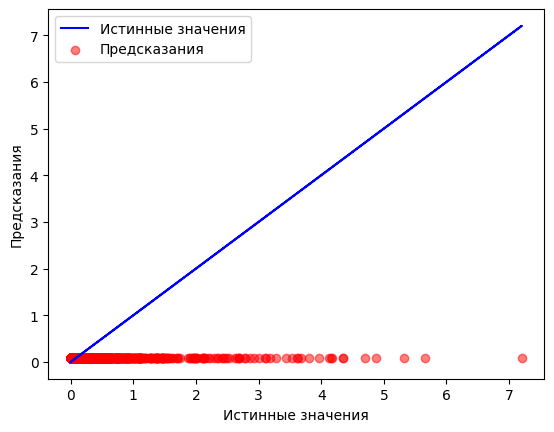

In [42]:
# Создание модели Lasso
lasso = sklearn.linear_model.Lasso(alpha=1.0, max_iter=200)
# Обучение модели
lasso.fit(x_train, y_train)
# Прогноз на обучающих данных
y_pred = lasso.predict(x_train)

# Вычисление MAPE (Mean Absolute Percentage Error)
mape_train = sklearn.metrics.mean_absolute_percentage_error(y_train, y_pred)
print(f'MAPE на обучающем наборе: {mape_train}')

# Построение графиков
plt.figure()
plt.plot(y_train.values, y_train.values, label='Истинные значения', color='blue')
plt.scatter(y_train.values, y_pred, label='Предсказания', color='red', alpha=0.5)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказания')
plt.legend()
plt.show()

In [43]:
mape_train

222034273562527.06

MAPE на обучающем наборе: 141835003433470.9


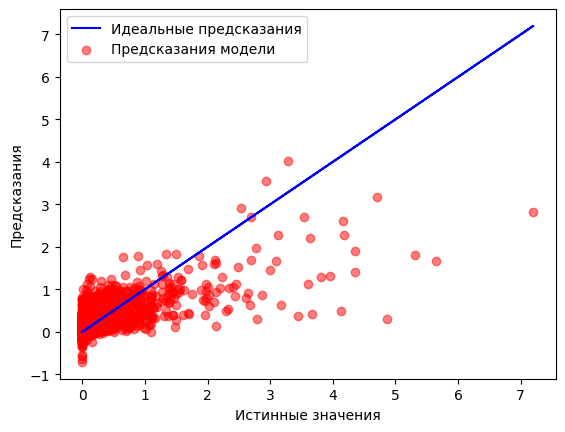

In [44]:
# Создание модели линейной регрессии
lr = sklearn.linear_model.LinearRegression()
# Обучение модели
lr.fit(x_train, y_train)
# Прогноз на обучающих данных
y_pred = lr.predict(x_train)

# Вычисление MAPE (Mean Absolute Percentage Error)
mape_train = sklearn.metrics.mean_absolute_percentage_error(y_train, y_pred)
print(f'MAPE на обучающем наборе: {mape_train}')

# Построение графиков
plt.figure()
plt.plot(y_train, y_train, label='Идеальные предсказания', color='blue')
plt.scatter(y_train, y_pred, label='Предсказания модели', color='red', alpha=0.5)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказания')
plt.legend()
plt.show()

In [45]:
mape_train

141835003433470.9

In [49]:
# коэффициента детерминации, который измеряет, насколько хорошо предсказанные значения соответствуют истинным
score = lr.score(x_train, y_train)
score

0.5163771239224607

In [50]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 8.6 MB/s eta 0:00:00


In [ ]:
# depth=12 — глубина деревьев решений
# train_pool — обучающий набор данных, включающий информацию о категориальных признаках
from catboost import CatBoostRegressor, Pool
catboost = CatBoostRegressor(iterations = 2000,
                             depth=12,
                             loss_function = 'MAPE', cat_features = categorical_features_nos)
x_train, x_test, y_train, y_test = train_test_split(data1, y, test_size = 0.2, random_state = 123)

train_pool = Pool(x_train, y_train, cat_features = categorical_features_nos)
test_pool = Pool(x_train, cat_features = categorical_features_nos)
catboost.fit(train_pool)
y_pred = catboost.predict(test_pool)
mape_train = sklearn.metrics.mean_absolute_percentage_error(y_train, y_pred)
mae_train = sklearn.metrics.mean_absolute_error(y_train, y_pred)
plt.figure()
plt.plot(y_train, y_train)
plt.scatter(y_train, y_pred)
plt.show()


In [51]:
from catboost import CatBoostRegressor, Pool

# Создание модели CatBoostRegressor
catboost = CatBoostRegressor(iterations=2000,
                             depth=12,
                             loss_function='MAPE',
                             cat_features=categorical_features_nos)

# Разделение данных на обучающие и тестовые наборы
x_train, x_test, y_train, y_test = train_test_split(data1, y, test_size=0.2, random_state=123)

# Создание объектов Pool
train_pool = Pool(x_train, y_train, cat_features=categorical_features_nos)
test_pool = Pool(x_test, cat_features=categorical_features_nos)

# Обучение модели
catboost.fit(train_pool)
# Прогнозирование на тестовом наборе
y_pred = catboost.predict(test_pool)

# Оценка модели на обучающих данных
mape_train = sklearn.metrics.mean_absolute_percentage_error(y_train, catboost.predict(train_pool))
mae_train = sklearn.metrics.mean_absolute_error(y_train, catboost.predict(train_pool))

# оценка модели на тестовой
mape_test = sklearn.metrics.mean_absolute_percentage_error(y_test, y_pred)
mae_test = sklearn.metrics.mean_absolute_error(y_test, y_pred)

print(f'MAPE на тестовом наборе: {mape_test}')
print(f'MAE на тестовом наборе: {mae_test}')

print(f'MAPE на тестовом наборе: {mape_train}')
print(f'MAE на тестовом наборе: {mae_train}')

# Построение графиков
plt.figure()
plt.plot(y_test, y_test, label='Идеальные предсказания', color='blue')
plt.scatter(y_test, y_pred, label='Предсказания модели', color='red', alpha=0.5)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказания')
plt.legend()
plt.show()

CatBoostError: Invalid type for cat_feature[non-default value idx=7369,feature_idx=2]=nan : cat_features must be integer or string, real number values and NaN values should be converted to string.

0:	learn: 0.0638971	total: 63.9ms	remaining: 2m 7s
1:	learn: 0.0632307	total: 185ms	remaining: 3m 5s
2:	learn: 0.0624988	total: 297ms	remaining: 3m 17s
3:	learn: 0.0618134	total: 422ms	remaining: 3m 30s
4:	learn: 0.0613605	total: 444ms	remaining: 2m 56s
5:	learn: 0.0605465	total: 563ms	remaining: 3m 7s
6:	learn: 0.0599081	total: 685ms	remaining: 3m 14s
7:	learn: 0.0594144	total: 758ms	remaining: 3m 8s
8:	learn: 0.0588019	total: 876ms	remaining: 3m 13s
9:	learn: 0.0581550	total: 983ms	remaining: 3m 15s
10:	learn: 0.0576644	total: 1.11s	remaining: 3m 21s
11:	learn: 0.0570804	total: 1.25s	remaining: 3m 26s
12:	learn: 0.0565177	total: 1.37s	remaining: 3m 29s
13:	learn: 0.0559796	total: 1.5s	remaining: 3m 32s
14:	learn: 0.0554761	total: 1.62s	remaining: 3m 34s
15:	learn: 0.0549725	total: 1.76s	remaining: 3m 38s
16:	learn: 0.0546224	total: 1.89s	remaining: 3m 40s
17:	learn: 0.0539786	total: 2.02s	remaining: 3m 42s
18:	learn: 0.0534712	total: 2.15s	remaining: 3m 43s
19:	learn: 0.0531081	total

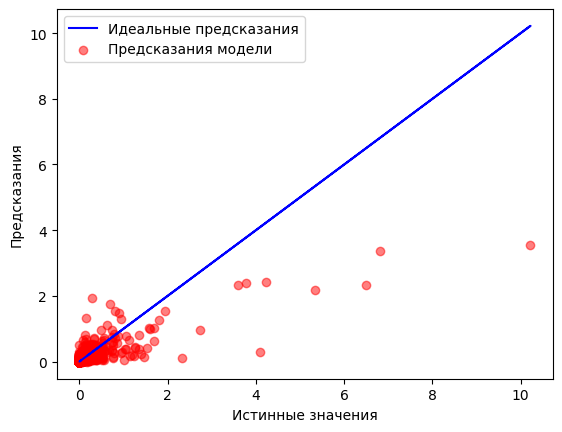

In [52]:
from catboost import CatBoostRegressor, Pool

# Убедитесь, что пропуски заполнены и категориальные признаки представлены в виде строк
for col in categorical_features:
    data1[col] = data1[col].fillna('missing').astype(str)

# Создание модели CatBoostRegressor
catboost = CatBoostRegressor(iterations=2000,
                             depth=12,
                             loss_function='MAPE',
                             cat_features=categorical_features_nos)

# Разделение данных на обучающие и тестовые наборы
x_train, x_test, y_train, y_test = train_test_split(data1, y, test_size=0.2, random_state=123)

# Создание объектов Pool
train_pool = Pool(x_train, y_train, cat_features=categorical_features_nos)
test_pool = Pool(x_test, cat_features=categorical_features_nos)

# Обучение модели
catboost.fit(train_pool)

# Прогнозирование на тестовом наборе
y_pred_test = catboost.predict(test_pool)

# Оценка модели
mape_train = sklearn.metrics.mean_absolute_percentage_error(y_train, catboost.predict(train_pool))
mae_train = sklearn.metrics.mean_absolute_error(y_train, catboost.predict(train_pool))

mape_test = sklearn.metrics.mean_absolute_percentage_error(y_test, y_pred_test)
mae_test = sklearn.metrics.mean_absolute_error(y_test, y_pred_test)

print(f'MAPE на обучающем наборе: {mape_train}')
print(f'MAE на обучающем наборе: {mae_train}')
print(f'MAPE на тестовом наборе: {mape_test}')
print(f'MAE на тестовом наборе: {mae_test}')

# Построение графиков
plt.figure()
plt.plot(y_test, y_test, label='Идеальные предсказания', color='blue')
plt.scatter(y_test, y_pred_test, label='Предсказания модели', color='red', alpha=0.5)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказания')
plt.legend()
plt.show()

In [54]:
mae_test

0.05612696155167721

In [71]:
# Чтение данных из файла CSV
test_data = pd.read_csv(r'/content/drive/MyDrive/Video_Games_Test.csv')

In [72]:
test_data

,Id,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,1,BeatMania IIDX 13: DistorteD,PS2,2007.0,Simulation,Konami Digital Entertainment,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Rugrats: Castle Capers,GBA,2001.0,Action,THQ,0.33,0.12,0.01,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Overlord II,PS3,2009.0,Action,Codemasters,0.11,0.15,0.06,72.0,42.0,7.6,24.0,Triumph Studios,T
3,4,Barbie as The Island Princess,GBA,2007.0,Adventure,Activision,0.16,0.06,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Petz: Hamsterz Life 2,GBA,2007.0,Misc,Ubisoft,0.01,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5011,5012,Valhalla Knights: Eldar Saga,Wii,2009.0,Role-Playing,Rising Star Games,0.10,0.01,0.01,35.0,17.0,6.7,19.0,"K2, Kurogane",T
5012,5013,WWF No Mercy,N64,2000.0,Fighting,THQ,1.20,0.27,0.02,NaN,NaN,NaN,NaN,NaN,NaN
5013,5014,Ty the Tasmanian Tiger,GC,2002.0,Platform,Electronic Arts,0.21,0.05,0.01,69.0,12.0,8.7,15.0,Krome Studios,E
5014,5015,Scooby-Doo! Unmasked,DS,2005.0,Platform,THQ,0.07,0.01,0.01,NaN,NaN,NaN,NaN,NaN,NaN


In [73]:
test_data.shape

(5016, 15)

In [75]:
# Сохранение столбца Id для последующего использования
ids = test_data['Id']

# Определение признаков
categorical_features = []
categorical_features_nos = []
numeric_features = []

# Определение категориальных и числовых признаков
i = 0
for col in test_data.columns:
    if col != 'Id':  # Исключаем столбец Id из обработки
        if test_data[col].dtype == object:
            categorical_features.append(col)
            categorical_features_nos.append(i)
        else:
            numeric_features.append(col)
    i += 1

# Заполнение пропусков и нормализация числовых признаков
test_data = test_data.fillna(-100)
test_data[numeric_features] = (test_data[numeric_features] - test_data[numeric_features].mean()) / test_data[numeric_features].std()

# Преобразование категориальных признаков с помощью one-hot кодирования
test_data_encoded = pd.get_dummies(test_data[categorical_features]).astype(int)

# Объединение числовых и закодированных категориальных признаков
x1 = pd.concat([test_data[numeric_features], test_data_encoded], axis=1)

# Восстановление столбца Id
x1 = pd.concat([ids, x1], axis=1)

# Проверка результата
x1


,Id,Year_of_Release,NA_Sales,EU_Sales,Other_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Name_-100,...,Developer_n-Space,Developer_oeFun,Developer_puzzle.tv,Rating_-100,Rating_E,Rating_E10+,Rating_EC,Rating_M,Rating_RP,Rating_T
0,1,0.124636,-0.410278,-0.316892,-0.259259,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0
1,2,0.101018,0.133744,-0.045053,-0.203639,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0
2,3,0.132509,-0.228937,0.022906,0.074459,1.050263,1.244661,1.108362,0.003071,0,...,0,0,0,0,0,0,0,0,0,1
3,4,0.124636,-0.146510,-0.180973,-0.259259,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0
4,5,0.124636,-0.393792,-0.316892,-0.259259,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5011,5012,0.132509,-0.245423,-0.294239,-0.203639,0.614622,0.856465,1.091485,-0.007751,0,...,0,0,0,0,0,0,0,0,0,1
5012,5013,0.097082,1.567985,0.294745,-0.148019,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0
5013,5014,0.104954,-0.064082,-0.203626,-0.203639,1.014940,0.778825,1.128989,-0.016408,0,...,0,0,0,0,1,0,0,0,0,0
5014,5015,0.116763,-0.294879,-0.294239,-0.203639,-0.974877,-0.960293,-0.909315,-0.265305,0,...,0,0,0,1,0,0,0,0,0,0


In [76]:
# Создание объекта Pool для тестовых данных
test_pool = Pool(test_data, cat_features=categorical_features_nos)

# Прогнозирование
y_pred_test = catboost.predict(test_pool)

# Проверка размеров данных и предсказаний
print(f"Размер test_data: {test_data.shape}")
print(f"Размер y_pred_test: {len(y_pred_test)}")


Размер test_data: (5016, 15)
Размер y_pred_test: 5016


In [80]:
y_pred_test

array([0.05690504, 0.00139111, 0.02105785, ..., 0.02386177, 0.01613574,
       0.03224607])

In [77]:
# Создание DataFrame с результатами
results = pd.DataFrame({
    'Id': test_data['Id'].values,
    'JP_Sales': y_pred_test
})

# Сохранение в CSV файл
results.to_csv('submission.csv', index=False)

In [79]:
from google.colab import files

# Выкачивание файла
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>